# Figure 3 — publication plotting

This notebook reads only the validated tables produced by the analysis
notebook. It creates Panels A–E, checks annotation bounds, and exports PNG,
SVG, PDF, and TIFF files. The styling matches Figures 1 and 2.


In [15]:
from pathlib import Path
import os
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    os.environ.get("MITOXY_PROJECT_ROOT", "/scratch/ar58064/mitoxy")
).resolve()
RAW_ROOT = PROJECT_ROOT / "data" / "raw"
REFERENCE_DIR = PROJECT_ROOT / "data" / "reference" / "figure_3"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "figure_3_clean"
FIGURE_DIR = PROJECT_ROOT / "figures" / "figure_3_clean"
for directory in [REFERENCE_DIR, OUTPUT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from PIL import Image as PILImage, ImageChops

BLUE = "#087EBD"
ORANGE = "#E36A00"
TEAL = "#00A67E"
PURPLE = "#8053A6"
DARK = "#202832"
MID = "#667386"
GRID = "#DDE3E9"
BAND = "#F2F5F8"
WHITE = "#FFFFFF"

mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 13,
    "axes.labelcolor": DARK, "text.color": DARK,
    "xtick.color": "#4E5968", "ytick.color": DARK,
    "axes.linewidth": 1.1, "figure.facecolor": WHITE,
    "axes.facecolor": WHITE, "savefig.facecolor": WHITE,
    "svg.fonttype": "none", "pdf.fonttype": 42,
})

def p_text(value):
    if value < 0.001:
        return f"{value:.1e}"
    return f"{value:.3f}"

def panel_letter(fig, letter):
    fig.text(0.025, 0.965, letter, fontsize=34, fontweight="bold",
             color=DARK, ha="left", va="top")

def clean_axes(ax, grid="x"):
    ax.grid(axis=grid, color=GRID, linewidth=1)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_color("#8B96A3")
    ax.spines["bottom"].set_color("#8B96A3")

def save_panel(fig, stem):
    paths = {}
    for suffix in ["png", "svg", "pdf"]:
        path = FIGURE_DIR / f"{stem}.{suffix}"
        fig.savefig(path, dpi=400, bbox_inches="tight", pad_inches=0.12)
        paths[suffix] = path
    return paths

def read_panel(stem):
    path = OUTPUT_DIR / stem
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run 01_Figure3_Analysis.ipynb first."
        )
    return pd.read_csv(path)

panel_a = read_panel("panel_a_pc1_loadings.csv")
panel_b = read_panel("panel_b_score_architectures.csv")
panel_c = read_panel("panel_c_cptac_multiomics.csv")
panel_d = read_panel("panel_d_single_gene_grade.csv")
panel_e = read_panel("panel_e_joint_models.csv")


Project root: /scratch/ar58064/mitoxy


## Panel A


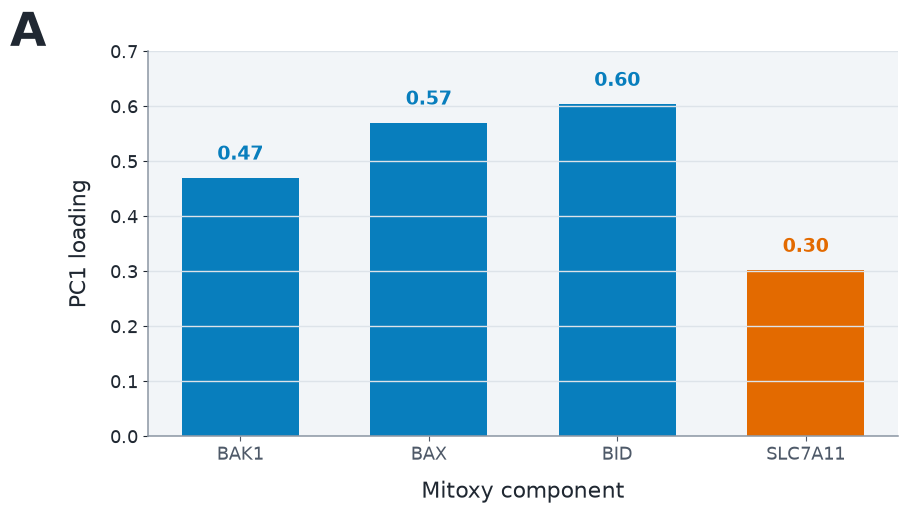

In [16]:
fig, ax = plt.subplots(figsize=(9.5, 5.5))
colors = [BLUE, BLUE, BLUE, ORANGE]
bars = ax.bar(panel_a["gene"], panel_a["PC1_loading"], color=colors, width=0.62)
ax.axhspan(0, 0.7, color=BAND, zorder=0)
for bar, value, color in zip(bars, panel_a["PC1_loading"], colors):
    ax.text(bar.get_x() + bar.get_width()/2, value + 0.025, f"{value:.2f}",
            ha="center", va="bottom", fontsize=14, fontweight="bold", color=color)
ax.set_ylim(0, 0.70)
ax.set_ylabel("PC1 loading", fontsize=16, labelpad=14)
ax.set_xlabel("Mitoxy component", fontsize=16, labelpad=12)
clean_axes(ax, "y")
panel_letter(fig, "A")
fig.subplots_adjust(left=0.17, right=0.96, top=0.89, bottom=0.19)
panel_a_paths = save_panel(fig, "figure_3a_pc1_loadings")
plt.show()


## Panel B


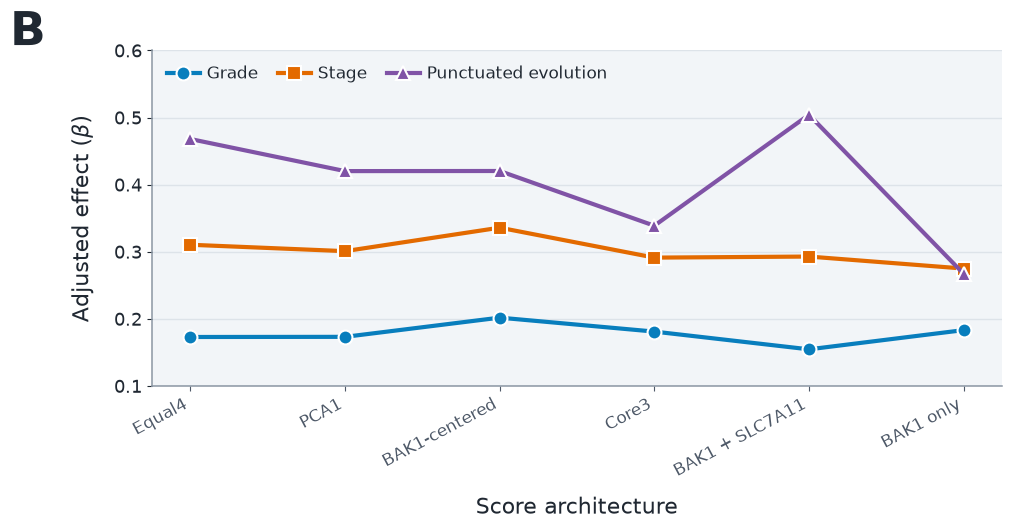

In [17]:
fig, ax = plt.subplots(figsize=(10.5, 5.5))
x = np.arange(len(panel_b))
series = [
    ("grade_beta", "Grade", BLUE, "o"),
    ("stage_beta", "Stage", ORANGE, "s"),
    ("punctuated_beta", "Punctuated evolution", PURPLE, "^"),
]
ax.axhspan(0.10, 0.60, color=BAND, zorder=0)
for column, label, color, marker in series:
    ax.plot(x, panel_b[column], color=color, linewidth=3, marker=marker,
            markersize=10, markeredgecolor=WHITE, markeredgewidth=1.5,
            label=label, zorder=3)
ax.set_xticks(x, panel_b["score_label"], rotation=28, ha="right", fontsize=12.5)
ax.set_ylim(0.10, 0.60)
ax.set_ylabel(r"Adjusted effect ($\beta$)", fontsize=16, labelpad=14)
ax.set_xlabel("Score architecture", fontsize=16, labelpad=12)
ax.legend(frameon=False, ncol=3, loc="upper left", fontsize=12,
          handlelength=2.0, columnspacing=1.2, handletextpad=0.4)
clean_axes(ax, "y")
panel_letter(fig, "B")
fig.subplots_adjust(left=0.16, right=0.97, top=0.89, bottom=0.28)
panel_b_paths = save_panel(fig, "figure_3b_score_architectures")
plt.show()


## Panel C


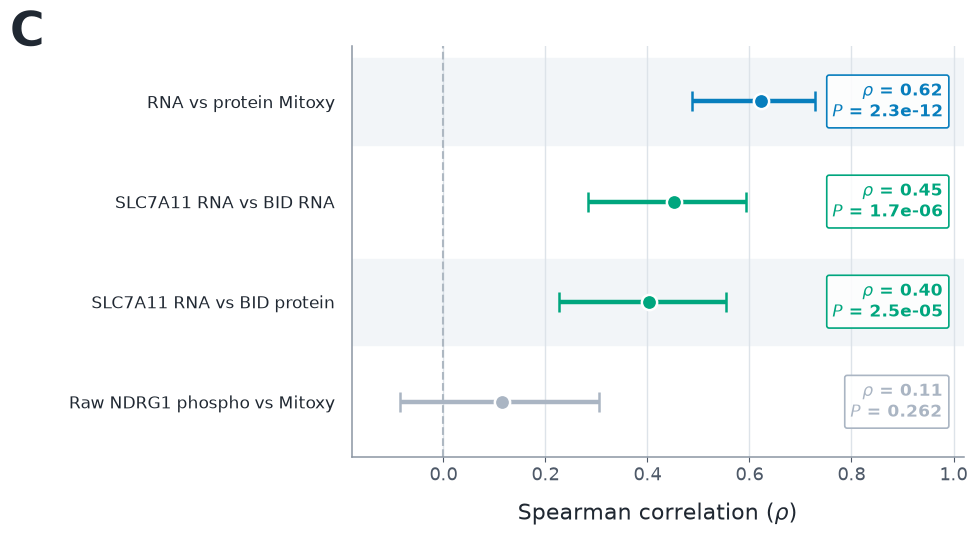

In [18]:
data = panel_c.iloc[::-1].reset_index(drop=True)
y = np.arange(len(data))
fig, ax = plt.subplots(figsize=(10.2, 5.7))
for i in range(len(data)):
    if i % 2 == 1:
        ax.axhspan(i - 0.43, i + 0.43, color=BAND, zorder=0)
colors = ["#AAB5C3", TEAL, TEAL, BLUE]
for i, (row, color) in enumerate(zip(data.itertuples(index=False), colors)):
    ax.errorbar(row.rho, i,
                xerr=[[row.rho-row.ci_low], [row.ci_high-row.rho]],
                fmt="o", color=color, ecolor=color, markersize=11,
                elinewidth=3.2, capsize=7, capthick=2,
                markeredgecolor=WHITE, markeredgewidth=1.8, zorder=3)
    ax.text(0.98, i, rf"$\rho$ = {row.rho:.2f}" + "\n" + rf"$P$ = {p_text(row.p_value)}",
            ha="right", va="center", fontsize=12.5, fontweight="bold", color=color,
            bbox={"boxstyle":"round,pad=0.32,rounding_size=0.14",
                  "facecolor":(1,1,1,0.84), "edgecolor":color, "linewidth":1.2})
ax.set_yticks(y, data["comparison"], fontsize=12.5)
ax.axvline(0, color="#AEB8C2", linestyle="--", linewidth=1.5)
ax.set_xlim(-0.18, 1.02)
ax.set_ylim(-0.55, len(data)-0.45)
ax.set_xlabel(r"Spearman correlation ($\rho$)", fontsize=16, labelpad=13)
ax.tick_params(axis="y", length=0, pad=12)
clean_axes(ax, "x")
panel_letter(fig, "C")
fig.subplots_adjust(left=0.36, right=0.96, top=0.90, bottom=0.18)
panel_c_paths = save_panel(fig, "figure_3c_cptac_multiomics")
plt.show()


## Panel D


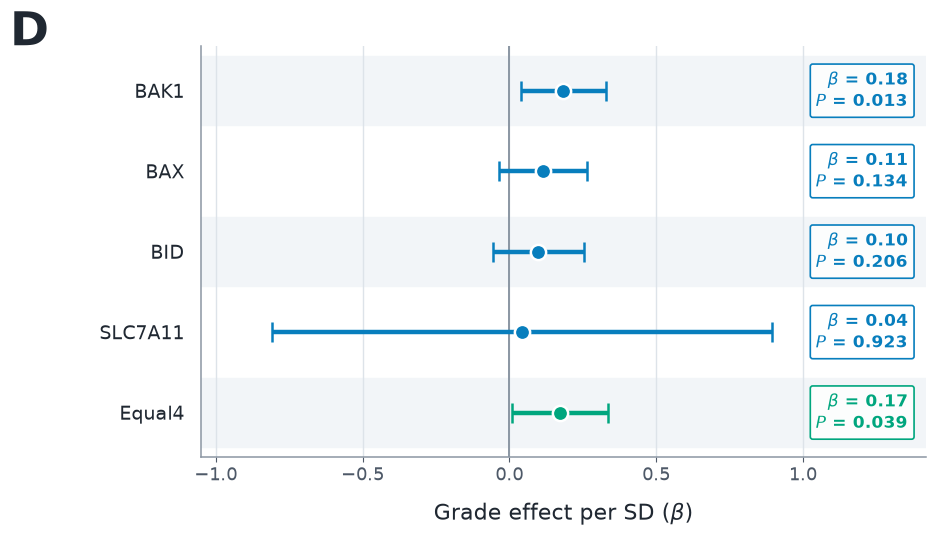

In [19]:
data = panel_d.iloc[::-1].reset_index(drop=True)
y = np.arange(len(data))
fig, ax = plt.subplots(figsize=(9.8, 5.7))
for i in range(len(data)):
    if i % 2 == 0:
        ax.axhspan(i - 0.43, i + 0.43, color=BAND, zorder=0)
for i, row in enumerate(data.itertuples(index=False)):
    color = TEAL if row.component == "Equal4" else BLUE
    ax.errorbar(row.beta, i,
                xerr=[[row.beta-row.ci_low], [row.ci_high-row.beta]],
                fmt="o", color=color, ecolor=color, markersize=11,
                elinewidth=3.2, capsize=7, capthick=2,
                markeredgecolor=WHITE, markeredgewidth=1.8, zorder=3)
    ax.text(1.36, i, rf"$\beta$ = {row.beta:.2f}" + "\n" + rf"$P$ = {p_text(row.p_value)}",
            ha="right", va="center", fontsize=12.5, fontweight="bold", color=color,
            bbox={"boxstyle":"round,pad=0.31,rounding_size=0.14",
                  "facecolor":(1,1,1,0.84), "edgecolor":color, "linewidth":1.2})
ax.set_yticks(y, data["component"], fontsize=13.5)
ax.axvline(0, color="#8B96A3", linewidth=1.4)
ax.set_xlim(-1.05, 1.42)
ax.set_ylim(-0.55, len(data)-0.45)
ax.set_xlabel(r"Grade effect per SD ($\beta$)", fontsize=16, labelpad=13)
ax.tick_params(axis="y", length=0, pad=12)
clean_axes(ax, "x")
panel_letter(fig, "D")
fig.subplots_adjust(left=0.22, right=0.96, top=0.90, bottom=0.18)
panel_d_paths = save_panel(fig, "figure_3d_single_gene_grade")
plt.show()


## Panel E


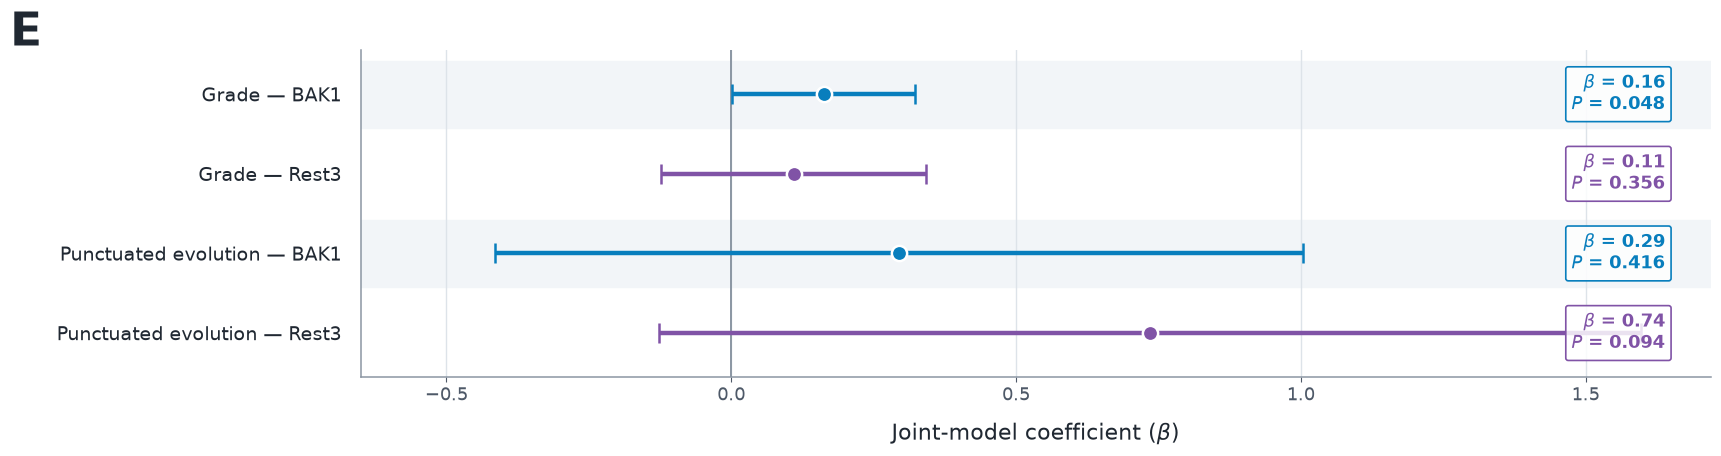

In [20]:
data = panel_e.copy()
data["label"] = data["endpoint"] + " — " + data["component"]
data = data.iloc[::-1].reset_index(drop=True)
y = np.arange(len(data))
fig, ax = plt.subplots(figsize=(18.0, 4.8))
for i in range(len(data)):
    if i % 2 == 1:
        ax.axhspan(i - 0.42, i + 0.42, color=BAND, zorder=0)
for i, row in enumerate(data.itertuples(index=False)):
    color = BLUE if row.component == "BAK1" else PURPLE
    ax.errorbar(row.beta, i,
                xerr=[[row.beta-row.ci_low], [row.ci_high-row.beta]],
                fmt="o", color=color, ecolor=color, markersize=11,
                elinewidth=3.2, capsize=7, capthick=2,
                markeredgecolor=WHITE, markeredgewidth=1.8, zorder=3)
    ax.text(1.64, i, rf"$\beta$ = {row.beta:.2f}" + "\n" + rf"$P$ = {p_text(row.p_value)}",
            ha="right", va="center", fontsize=12.7, fontweight="bold", color=color,
            bbox={"boxstyle":"round,pad=0.32,rounding_size=0.14",
                  "facecolor":(1,1,1,0.84), "edgecolor":color, "linewidth":1.2})
ax.set_yticks(y, data["label"], fontsize=13.5)
ax.axvline(0, color="#8B96A3", linewidth=1.4)
ax.set_xlim(-0.65, 1.72)
ax.set_ylim(-0.55, len(data)-0.45)
ax.set_xlabel(r"Joint-model coefficient ($\beta$)", fontsize=16, labelpad=13)
ax.tick_params(axis="y", length=0, pad=14)
clean_axes(ax, "x")
panel_letter(fig, "E")
fig.subplots_adjust(left=0.22, right=0.97, top=0.88, bottom=0.20)
panel_e_paths = save_panel(fig, "figure_3e_joint_models")
plt.show()


## Assemble Figure 3


Saved:
/scratch/ar58064/mitoxy/figures/figure_3_clean/Figure_3_complete.png
/scratch/ar58064/mitoxy/figures/figure_3_clean/Figure_3_complete.tiff


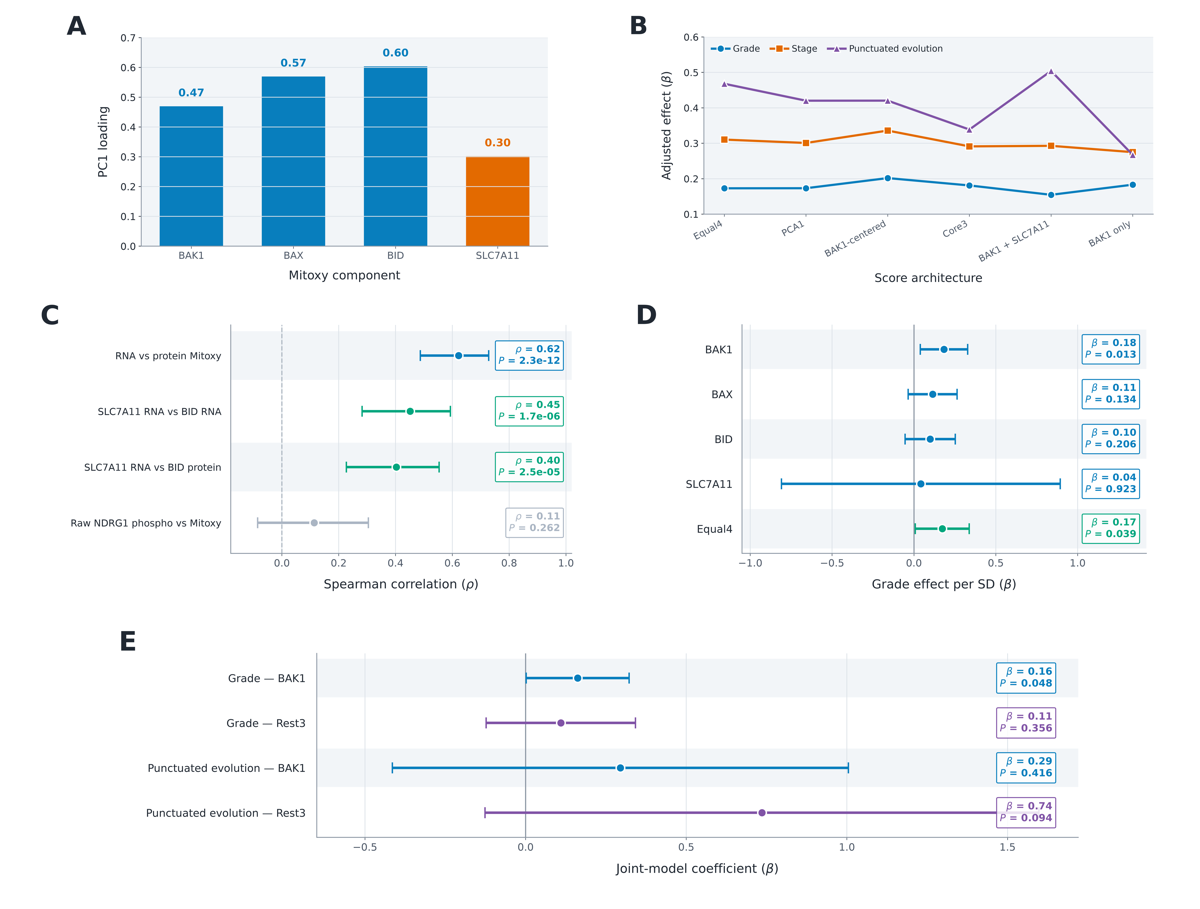

In [21]:
panel_paths = {
    "A": panel_a_paths["png"], "B": panel_b_paths["png"],
    "C": panel_c_paths["png"], "D": panel_d_paths["png"],
    "E": panel_e_paths["png"],
}

def trim_image(image, border=35):
    image = image.convert("RGB")
    background = PILImage.new("RGB", image.size, "white")
    box = ImageChops.difference(image, background).getbbox()
    if box is None:
        return image
    l, u, r, b = box
    return image.crop((max(0,l-border), max(0,u-border),
                       min(image.width,r+border), min(image.height,b+border)))

def place_contained(canvas, image_path, box):
    left, top, right, bottom = box
    image = trim_image(PILImage.open(image_path))
    image.thumbnail((right-left, bottom-top), PILImage.Resampling.LANCZOS)
    x = left + (right-left-image.width)//2
    y = top + (bottom-top-image.height)//2
    canvas.paste(image, (x,y))

canvas = PILImage.new("RGB", (6400, 4850), "white")
boxes = {
    "A": (120, 60, 3160, 1530), "B": (3240, 60, 6280, 1530),
    "C": (120, 1600, 3160, 3180), "D": (3240, 1600, 6280, 3180),
    "E": (620, 3300, 5780, 4740),
}
for letter, path in panel_paths.items():
    place_contained(canvas, path, boxes[letter])

final_png = FIGURE_DIR / "Figure_3_complete.png"
final_tiff = FIGURE_DIR / "Figure_3_complete.tiff"
canvas.save(final_png, dpi=(400,400))
canvas.save(final_tiff, dpi=(400,400), compression="tiff_lzw")
print("Saved:")
print(final_png)
print(final_tiff)
display(canvas.resize((1200, 909)))
